# WHAT Design (artist-year target)

## Summary

**What the notebook covers:** the design of the WHAT target (does the next stylistic move introduce a style the artist has not used before): (1) unit of prediction, (2) validation against the Work-level target, (3) population and prevalence, (4) label loss, (5) history and the volume confound, (6) folds and the exact label-resolution rule, (7) baselines, (8) the kill gate pass rule, (9) open items, (10) the feature audit, (11) the kill gate, (12) the gate diagnostics, and Appendix A (style versus genre change). All logic lives in `src/what_target.py`, `src/backtesting.py`, `src/baselines.py` and `src/models.py`; the notebook only imports and calls it, and plots.

**Key findings**

- **Unit:** WHAT is predicted per artist and calendar year. More than half of the Work-level transitions go to a Work of the same year, whose order is pseudo-random.
- **Consistency:** the artist-year label never loses a positive of the Work-level label (0 violations) and agrees exactly when the next year has a single Work (0 mismatches).
- **Prevalence:** about 31% at artist-year level against about 20% at Work level, stable over the five test tranches. A minimum of 3 previous Works is confirmed.
- **Label loss:** 71.5% of eligible rows are labelled. The loss from missing style tags is concentrated by genre (about 55x between Hip Hop and Electronic), not by period or history.
- **Volume:** the label rate depends strongly on the number of Works in the next active year (diagnostic only, never a feature). The history gradient survives with volume held fixed.
- **Folds:** an exact resolution rule replaces the fixed 2-year gap, closing a leak of 5.2% to 5.7% of the fixed-gap train rows.
- **Baselines:** history adds 3.2 to 3.7 PR-AUC points over a constant. The current-year Work count adds 0.15 to 1.2 more. The reference for the kill gate is the history and volume lookup baseline.
- **Kill gate:** the model (XGBoost stage 0 settings, 25 inputs, one configuration) beats baseline (c) in 5 of 5 folds by +11.3 to +14.1 PR-AUC points with no fold broken, so the verdict is PASS. Pooled ROC-AUC is 0.6732 against 0.5712.
- **Diagnostics:** the gain is larger for artists with no row in the train table (+15.3 against +10.5 points), holds in every next-year volume bucket, and no single feature group carries it. These are hypotheses, and no feature change follows.

**After the gate** (done in later work, logged in `docs/decisions.md`)

- **Five-model comparison** (`05_what_models.ipynb`, same folds and same 25 inputs): Logistic Regression, Naive Bayes, Random Forest, HistGradientBoosting and XGBoost stage 0 are all above baseline (c) in 5 of 5 folds. The three tree models are tied (pairwise differences of at most 0.57 PR-AUC points against interval widths of 0.010 to 0.016). Logistic Regression recovers 8.73 and Naive Bayes 6.63 of the 12.76 points of the XGBoost gain over (c).
- **Staged XGBoost tuning:** 69 log rows (stage 0 plus 68 trials). The best trial, `m_lr_0.012`, gains +0.408 points in mean PR-AUC over stage 0, but its interval lower bound is above the stage 0 upper bound in 0 of 5 folds (4 required by the adoption rule), so stage 0 is kept.
- **Sealed holdout, evaluated once:** the training rows have `year` < 2018 and `next_active_year` < 2018 (687,628 rows). The test rows are the labelled rows with `next_active_year` of 2023 or earlier: 143,228 rows from 71,523 artists, effectively 2018 to 2022. Stage 0 has PR-AUC 0.4986 [0.4932, 0.5036] and ROC-AUC 0.6781 [0.6748, 0.6813], against 0.3464 and 0.5586 for baseline (c) and a positive rate of 0.3128. The signal is moderate, not reliable case by case. No re-run is allowed on this holdout.


## 0. Data Loading

### Question: which data does every later section rely on, and how large is it?

The Works table and the Work-level snapshots are loaded once here and reused by every section. The artist-year table and the WHAT modeling table are built from the Works table by functions in `src/what_target.py`; nothing is cached.

In [1]:
import sys  # needed to extend the module search path
sys.path.append('../src')  # makes src/ importable from inside notebooks/
import matplotlib.pyplot as plt  # plotting library for the charts
import pandas as pd  # dataframes returned by the functions in src/
from what_target import build_artist_years, build_what_table  # target and modeling table, live in src/what_target.py

COLOR_A = '#1f77b4'  # artist-year level (A), the same colour in every chart
COLOR_B = '#d95f02'  # Work level (B), the same colour in every chart
plt.rcParams.update({'font.size': 12, 'axes.titlesize': 13})  # sizes readable at presentation size

works_df = pd.read_parquet('../data/processed/works_checkpoint.parquet')  # cleaned Works table, one row per Work
snapshots_df = pd.read_parquet('../data/processed/snapshots.parquet', columns=['artist_id', 'work_id', 'year', 'history_count', 'new_style'])  # Work-level snapshots, only the columns the checks need
artist_years = build_artist_years(works_df)  # one row per artist and calendar year, with the artist-year label
what_table = build_what_table(artist_years)  # rows WHAT is trained and evaluated on: history >= 3 and a label, all years
print(f"Works: {len(works_df):,} | snapshots: {len(snapshots_df):,} | artist-years: {len(artist_years):,} | WHAT table rows (all years): {len(what_table):,}")  # row counts only

Works: 5,949,217 | snapshots: 5,438,765 | artist-years: 3,294,781 | WHAT table rows (all years): 985,218


**Reading.** The Works table has 5,949,217 rows and the Work-level snapshots 5,438,765. The artist-year table has 3,294,781 rows, of which 985,218 (all years) enter the WHAT table because they have at least 3 previous Works and a label.

## 1. Target Definition

### Question: at which level should WHAT be predicted, one row per Work or one row per artist and calendar year?

At Work level, `new_style` asks whether the next Work brings a style not seen so far. The data only knows the year of a Work, and Works of the same year are ordered by a seeded pseudo-random order (documented in `docs/decisions.md`). If many transitions go to a Work of the same year, the label depends on an order that is not real chronology. The first check measures how many.

In [2]:
from what_target import same_year_transition_share  # share of transitions that go to a Work of the same year, lives in src/what_target.py

same_year_transition_share(snapshots_df).round(4)  # development years and all years; only the presence of a label selects rows, its values are never read

,transitions,to_same_year,same_year_share
population,,,
development (year < 2018),1761260,957644,0.5437
all years,2423318,1381521,0.5701


### Interpretation

Between 54.4% (development years) and 57.0% (all years) of the Work-level transitions with at least 3 previous Works go to a Work of the same year. For these transitions the next Work is decided by the seeded pseudo-random order inside the year, not by real chronology, because the data only knows the year. A Work-level label that compares the next Work with the styles seen so far therefore depends on an order that does not exist in the data for more than half of the transitions. The all-years row describes the structure of the data only: it uses which rows have a label, never the label values.

### Decision

The Work-level target is not used for WHAT. The unit of prediction is moved to the artist-year (next section).


### Question: what does the artist-year target look like on one real artist?

The artist is chosen by a fixed rule: the first `artist_id` with 5 or 6 active years, all of them in development years, with at least one row that survives the WHAT table filter (at least 3 previous Works and a label) and at least one such row labelled 1. The column `in_what_table` shows which rows survive the filter.

In [3]:
from what_target import example_artist_years  # one real artist chosen by a fixed rule, lives in src/what_target.py

example = example_artist_years(artist_years)  # first artist with 5 or 6 active years, a labelled eligible row and a positive one, development years only
example  # one row per active year, style sets as text

,artist_id,year,history_count,n_works_year,styles_seen,next_active_year,next_year_styles,new_style_year,in_what_table
0,117.0,1991,0,1,"Breakbeat, Downtempo, Garage House, House, Soul",1992.0,"Breakbeat, Hardcore, House",1.0,False
1,117.0,1992,1,1,"Breakbeat, Downtempo, Garage House, Hardcore, ...",1997.0,"Broken Beat, House, Tech House",1.0,False
2,117.0,1997,2,1,"Breakbeat, Broken Beat, Downtempo, Garage Hous...",1998.0,House,0.0,False
3,117.0,1998,3,1,"Breakbeat, Broken Beat, Downtempo, Garage Hous...",2009.0,"Tech House, Techno",1.0,True
4,117.0,2009,4,1,"Breakbeat, Broken Beat, Downtempo, Garage Hous...",NaN,,NaN,False


In [4]:
works_df[works_df['artist_id'] == example['artist_id'].iloc[0]].sort_values('year', na_position='first')[['year', 'title', 'styles']]  # raw Works of the example artist, the undated one first

,year,title,styles
2912,NaN,Young Heart Run Free / Only You,"[Breakbeat, House, Soul]"
2908,1991.0,Float On,"[Downtempo, Soul, Garage House]"
2909,1992.0,Only You,"[Breakbeat, House, Hardcore]"
2911,1997.0,The Future Remembrance EP,"[House, Broken Beat, Tech House]"
2910,1998.0,Sex Food EP,[House]
2907,2009.0,Deep Techhouse&Techno,"[Tech House, Techno]"


### Interpretation

The example is the first artist with 5 active years in development, at least one eligible and labelled row, and at least one positive among those rows (artist 117). The five rows show how the target is built. The vocabulary in `styles_seen` includes the styles of the artist's undated Work (Breakbeat, House, Soul) from the first row on, so the 1991 row starts with five styles rather than three. The 1991 and 1992 labels are 1 because the next active years bring Hardcore and then Broken Beat and Tech House. The 1997 label is 0 because the 1998 Work only repeats House. The 1998 label is 1 because the next active year, 2009, brings Techno, after a gap of 11 years. The 2009 row has no next active year and no label.

Only the 1998 row passes the WHAT table filter (`in_what_table` is True): the earlier rows have fewer than 3 previous Works, and the last one has no label. The raw Works printed above agree with the table: each next-year style set equals the tags of that year's Work, and the history counts are the dated Works strictly before each year.

### Decision

WHAT is modeled at artist-year level. A row is an artist and a calendar year, and the target is 1 when the Works of the artist's next active year contain at least one style absent from every style seen through the end of the current year (styles of undated Works count as seen). The target is missing when there is no next active year or the next year's Works carry no style tags. The within-year order of Works plays no role. Logged in `docs/decisions.md`.


## 2. Validation Against the Work-Level Target

### Question: is the artist-year label consistent with the Work-level label it replaces, and where exactly do the two differ?

The last Work of each artist-year, in the file order of the snapshots, is joined to its artist-year row (development years only, both labels present). Two properties must hold. If the Work-level label of the last Work is 1, the artist-year label must be 1, because the next year's union of styles contains the next Work's styles. If the next active year has exactly one Work, the two labels must be identical. Where the next year has several Works, the artist-year label may see positives the Work-level label cannot.

In [5]:
from what_target import crosscheck_levels  # consistency check between the two levels, lives in src/what_target.py

crosscheck = crosscheck_levels(snapshots_df, artist_years)  # last Work of each artist-year against its artist-year row, development years only
print('violation examples stored:', len(crosscheck.attrs['examples']))  # 0 means the two checks found nothing to show
crosscheck.round(4)  # rows, count and share per check

violation examples stored: 0


,check,rows,count,share
0,dev_last_work_rows,2555349,2555349,1.0000
1,dropped_only_new_style_nan,2555349,59873,0.0234
2,dropped_only_new_style_year_nan,2555349,0,0.0000
3,dropped_both_nan,2555349,942181,0.3687
4,implication,524587,0,0.0000
5,equality_single_next_work,1045826,0,0.0000
6,info_next_2,268921,31367,0.1166
7,info_next_3_4,162882,33993,0.2087
8,info_next_5_plus,75666,25309,0.3345


### Interpretation

The two consistency checks both pass with zero violations. Among 524,587 last Works of a year labelled 1 at Work level, none has an artist-year label of 0. Among 1,045,826 artist-years whose next active year has exactly one Work, the two labels are identical in every case. The artist-year label is therefore a strict superset of the Work-level label: it never loses a positive that the Work-level label sees, and it agrees exactly when the next year has a single Work.

Where the next year has several Works, the artist-year label sees positives that the Work-level label cannot: 11.7% of compared rows when the next year has 2 Works (31,367 of 268,921), 20.9% with 3 or 4 Works (33,993 of 162,882) and 33.4% with 5 or more (25,309 of 75,666). These are cases where a new style appears in a Work that is not the first one in the arbitrary within-year order. The share grows with the number of Works, as expected.

Of 2,555,349 last Works of development years, 942,181 (36.9%) have no label at either level, mostly an artist's last active year or a next year without style tags. A further 59,873 (2.3%) have no Work-level label only: the first Work of the next year has no style tags, but a later Work of that year does. These are the cases where the Work-level label depends on the arbitrary order inside the year and the artist-year label does not. No row has an artist-year label missing while the Work-level label exists, by construction.

### Decision

The artist-year target is consistent with the Work-level target on development years, and the differences are the expected ones. Validation passes and the target stays as defined. Logged in `docs/decisions.md`.


## 3. Population and Prevalence

### Question: how large is the population WHAT covers at each level, how frequent is the label per test window, and is a minimum of 3 previous Works still stable in the artist-year unit?

Level A is the artist-year table and level B the Work-level table, both with at least 3 previous Works. The windows are the five WHEN test tranches. For the sealed holdout (2018 to 2023) only the number of eligible rows and artists is reported; no label statistic is computed there.

In [6]:
from what_target import prevalence_by_fold  # label rate per window and level, lives in src/what_target.py

by_fold = prevalence_by_fold(snapshots_df, artist_years)  # A and B on the same windows and the same history rule; the holdout row has counts only
by_fold.round(4)  # eligible rows and artists, NaN share, labelled rows and rate per window and level

eligible_rows  eligible_artists  nan_share  \
window            level                                                     
development       work               2320628            293586     0.2410   
                  artist_year        1067817            267339     0.2851   
1993-1997         work                158507             46508     0.2475   
                  artist_year          80172             42481     0.2748   
1998-2002         work                198546             60103     0.2494   
                  artist_year         103420             55360     0.2791   
2003-2007         work                249927             77361     0.2440   
                  artist_year         131239             71203     0.2908   
2008-2012         work                345968            103813     0.2112   
                  artist_year         172976             94955     0.2967   
2013-2017         work                465635            131613     0.2139   
                  artist_year         228256            121756     0.3140   
holdout 2018-2023 work                698937            163224        NaN   
                  artist_year         312392            151788        NaN   

                               labelled_rows  prevalence  
window            level                                   
development       work             1761260.0      0.1958  
                  artist_year       763371.0      0.3093  
1993-1997         work              119273.0      0.2154  
                  artist_year        58141.0      0.3064  
1998-2002         work              149025.0      0.2141  
                  artist_year        74558.0      0.3018  
2003-2007         work              188954.0      0.2197  
                  artist_year        93072.0      0.3161  
2008-2012         work              272907.0      0.2200  
                  artist_year       121659.0      0.3266  
2013-2017         work              366027.0      0.2026  
                  artist_year       156591.0      0.3228  
holdout 2018-2023 work                   NaN         NaN  
                  artist_year            NaN         NaN

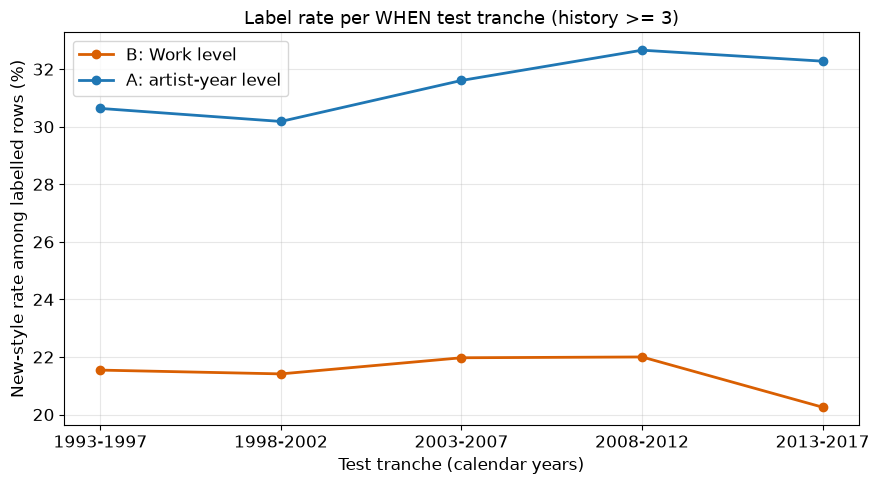

In [7]:
tranches = by_fold.drop(index='development', level='window').dropna(subset=['prevalence'])  # five test tranches; the holdout row has no prevalence (sealed)
fig, ax = plt.subplots(figsize=(9, 5))  # label rate per test tranche, both levels
for level, color, label in [('work', COLOR_B, 'B: Work level'), ('artist_year', COLOR_A, 'A: artist-year level')]:  # one colour per level in every chart
    series = tranches.xs(level, level='level')['prevalence'] * 100  # rate in %
    ax.plot(series.index, series.values, marker='o', linewidth=2, color=color, label=label)  # one line per level
ax.set_xlabel('Test tranche (calendar years)')  # axis label
ax.set_ylabel('New-style rate among labelled rows (%)')  # axis label with unit
ax.set_title('Label rate per WHEN test tranche (history >= 3)')  # chart title
ax.legend()  # level names
ax.grid(alpha=0.3)  # light guide lines
plt.tight_layout()  # avoid clipped labels
plt.show()  # draw the chart

In [8]:
from what_target import threshold_sensitivity  # label rate by minimum history, lives in src/what_target.py

sensitivity = threshold_sensitivity(artist_years, thresholds=(0, 1, 2, 3, 4, 5, 7))  # artist-year level, development years only
sensitivity.round(4).T  # thresholds as columns, so the long names stay readable

min_previous_works,0,1,2,3,4,5,7
eligible_rows,2.555349e+06,1.710644e+06,1.335598e+06,1.067817e+06,887392.0000,758359.0000,586553.0000
eligible_artists,8.447050e+05,4.942930e+05,3.710520e+05,2.673390e+05,202338.0000,159612.0000,108598.0000
artists_removed,0.000000e+00,3.504120e+05,4.736530e+05,5.773660e+05,642367.0000,685093.0000,736107.0000
nan_share,3.687000e-01,3.247000e-01,3.117000e-01,2.851000e-01,0.2645,0.2486,0.2264
labelled_rows,1.613168e+06,1.155162e+06,9.193200e+05,7.633710e+05,652714.0000,569825.0000,453740.0000
prevalence,3.971000e-01,3.468000e-01,3.242000e-01,3.093000e-01,0.2982,0.2891,0.2757
prevalence_1993_1997,4.020000e-01,3.447000e-01,3.209000e-01,3.064000e-01,0.2952,0.2878,0.2741
prevalence_1998_2002,3.962000e-01,3.430000e-01,3.181000e-01,3.018000e-01,0.2906,0.2813,0.2650
prevalence_2003_2007,4.111000e-01,3.585000e-01,3.335000e-01,3.161000e-01,0.3040,0.2936,0.2772
prevalence_2008_2012,4.189000e-01,3.668000e-01,3.427000e-01,3.266000e-01,0.3150,0.3042,0.2883


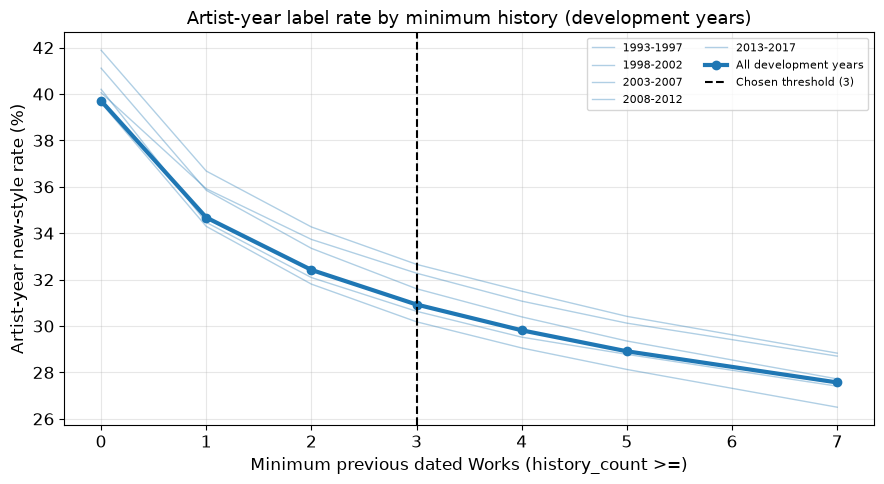

In [9]:
fig, ax = plt.subplots(figsize=(9, 5))  # label rate by minimum history, overall and per test tranche
tranche_columns = [c for c in sensitivity.columns if c.startswith('prevalence_') and c != 'prevalence']  # one column per WHEN test tranche
for column in tranche_columns:  # thin lines, one per tranche
    ax.plot(sensitivity.index, sensitivity[column] * 100, color=COLOR_A, alpha=0.35, linewidth=1, label=column.replace('prevalence_', '').replace('_', '-'))  # tranche years
ax.plot(sensitivity.index, sensitivity['prevalence'] * 100, color=COLOR_A, linewidth=3, marker='o', label='All development years')  # thick line, overall
ax.axvline(3, color='black', linestyle='--', label='Chosen threshold (3)')  # chosen value
ax.set_xlabel('Minimum previous dated Works (history_count >=)')  # axis label
ax.set_ylabel('Artist-year new-style rate (%)')  # axis label with unit
ax.set_title('Artist-year label rate by minimum history (development years)')  # chart title
ax.legend(fontsize=8, ncol=2)  # line names
ax.grid(alpha=0.3)  # light guide lines
plt.tight_layout()  # avoid clipped labels
plt.show()  # draw the chart

### Interpretation

**Population.** With at least 3 previous Works, the development years hold 2,320,628 Work-level rows (293,586 artists) and 1,067,817 artist-year rows (267,339 artists). The artist-year table has about 2.2 times fewer rows, because several Works of one year collapse into one row, while the number of artists changes little. The holdout window (2018 to 2023) is shown with counts only: 698,937 Work-level rows and 312,392 artist-year rows, and no label statistic.

**Prevalence.** The artist-year label is more frequent than the Work-level label in every window: 30.9% against 19.6% over development, and between 30.2% and 32.7% against 20.3% to 22.0% over the five test tranches. A union of styles over a whole year has more chances to contain something new, and the gap is the share of positives the Work-level label cannot see (section 2). The artist-year rate is stable over time (30.2% to 32.7%), with a slight upward drift. The share of eligible rows without a label is higher at artist-year level (28.5% against 24.1% over development) and grows over time at that level (27.5% in 1993-1997 to 31.4% in 2013-2017), because more artist-years sit at the end of a career or before a year without style tags (section 4).

**Threshold.** The rate falls smoothly as the minimum history rises: 34.7%, 32.4%, 30.9%, 29.8%, 28.9% and 27.6% at thresholds 1, 2, 3, 4, 5 and 7, about 1 to 1.5 points per step from threshold 2 on. There is no cliff. The profile over the five tranches is the same at every threshold: lowest in 1998-2002 and highest in 2008-2012, with a spread of 2 to 3 points. Threshold 3 keeps 267,339 of the 844,705 development artists (about 32%), so WHAT covers a smaller population than WHEN, which uses all snapshots.

### Decision

WHAT is modeled at artist-year level with a minimum of 3 previous Works, the same value as at Work level. The threshold is confirmed stable in the new unit. The smaller covered population is a limitation to state in the documentation and the demo. Logged in `docs/decisions.md`.


## 4. Label Loss

### Question: why do eligible artist-years lose their label, is the loss concentrated in particular genres or periods, and what would a more tolerant definition recover?

A label is missing for one of two reasons besides being present: the artist has no next active year, or the next active year exists but its Works carry no style tags. The second case is the one a tolerant definition could address, by using the next year that does carry style tags.

In [10]:
from what_target import label_loss_breakdown  # label loss analysis, lives in src/what_target.py

loss = label_loss_breakdown(works_df, artist_years)  # dict of tables, development years and history >= 3 only
loss['causes'].round(4)  # labelled rows, rows without a next active year, rows whose next year has no style tags

,rows,share
labelled,763371,0.7149
no_next_active_year,179128,0.1678
next_year_without_styles,125318,0.1174
eligible_total,1067817,1.0000


In [11]:
loss['recovery'].round(4)  # rows a tolerant definition would recover, extra delay in years and the label rate they would get

,value
cause_c_rows,125318.0000
recoverable_rows,76458.0000
not_recoverable_rows,48860.0000
recoverable_styled_year_at_or_after_holdout_start,14137.0000
recoverable_rows_in_prevalence,62321.0000
extra_delay_years_p50,2.0000
extra_delay_years_p75,5.0000
extra_delay_years_p90,10.0000
extra_delay_years_p99,29.0000
prevalence_recovered_rows,0.3999


In [12]:
loss['by_window'].round(4)  # same shares for the five WHEN test tranches and all earlier development years

,eligible_rows,cause_c_share,recovered_share
year,,,
before 1993,351754,0.1317,0.0906
1993-1997,80172,0.1273,0.0834
1998-2002,103420,0.1251,0.0772
2003-2007,131239,0.1225,0.0707
2008-2012,172976,0.1075,0.0585
2013-2017,228256,0.0928,0.0461


In [13]:
display(loss['by_genre'].round(4))  # same shares by primary genre (fake tag excluded), overall row first
print('artists without a valid genre:', loss['by_genre'].attrs['artists_without_valid_genre'])  # counts of artists left with no genre tag
loss['by_history_bucket'].round(4)  # same shares by prior-work bucket

,eligible_rows,cause_c_share,recovered_share
all genres,1067817,0.1174,0.0716
Electronic,247980,0.0058,0.0036
Rock,241123,0.0957,0.0578
Pop,183242,0.1702,0.1054
"Folk, World, & Country",153036,0.1791,0.1031
Jazz,63571,0.2050,0.1346
Latin,54553,0.1204,0.0817
Hip Hop,39030,0.3182,0.1693
Funk / Soul,34507,0.0914,0.0630
Reggae,25654,0.1146,0.0809


artists without a valid genre: {'all_artists': 0, 'eligible_artists': 0}


,eligible_rows,cause_c_share,recovered_share
prior_work_bucket,,,
3-5,406123,0.1115,0.0562
6-10,261646,0.1197,0.0702
11-20,188535,0.1228,0.0818
21-50,142289,0.1245,0.0930
51+,69224,0.1136,0.0959


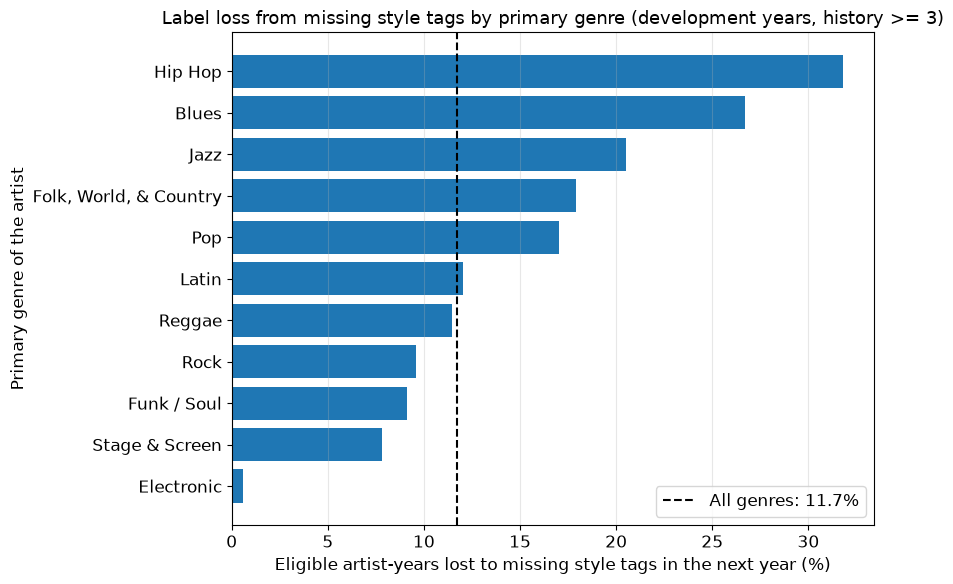

In [14]:
genre_rows = loss['by_genre'].drop(index='all genres').sort_values('cause_c_share')  # genres sorted from the smallest to the largest loss
overall_share = loss['by_genre'].loc['all genres', 'cause_c_share'] * 100  # overall share, the reference line
fig, ax = plt.subplots(figsize=(9, 6))  # horizontal bars read best with long genre names
ax.barh(genre_rows.index, genre_rows['cause_c_share'] * 100, color=COLOR_A)  # one bar per primary genre
ax.axvline(overall_share, color='black', linestyle='--', label=f"All genres: {overall_share:.1f}%")  # overall reference
ax.set_xlabel('Eligible artist-years lost to missing style tags in the next year (%)')  # axis label with unit
ax.set_ylabel('Primary genre of the artist')  # axis label
ax.set_title('Label loss from missing style tags by primary genre (development years, history >= 3)')  # chart title
ax.legend(loc='lower right')  # reference line name
ax.grid(axis='x', alpha=0.3)  # light guide lines
plt.tight_layout()  # avoid clipped labels
plt.show()  # draw the chart

### Interpretation

**Where the labels go.** Of the 1,067,817 eligible development artist-years, 763,371 (71.5%) are labelled. 179,128 (16.8%) have no next active year, which is intrinsic: WHAT is conditional on a future release, and WHEN covers the case of no release. The remaining 125,318 (11.7%) have a next active year whose Works carry no style tags.

**What a tolerant definition would recover.** For 76,458 of those 125,318 rows (61.0%) a later active year with style tags exists, and for 48,860 (39.0%) none does. The extra delay between the immediate next active year and the next styled year is long and variable: median 2 years, 75th percentile 5, 90th percentile 10, 99th percentile 29 (these use years only). Of the 76,458 recoverable rows, 14,137 have their next styled year in 2018 or later. Their label would use style tags of holdout-year Works, so they are counted but left out of every rate. The other 62,321 would have a label rate of 40.0% against 30.9% for the currently labelled rows, because the horizon is longer and variable. Adding them would lift the overall rate to 31.6% but would mix two different horizons into one label.

**Where the loss concentrates.** By period and by history the share lost to missing style tags is fairly even: it falls from 13.2% before 1993 to 9.3% in 2013-2017 (a spread of 1.42x), and stays between 11.2% and 12.5% across history buckets (1.12x). By primary genre it is highly uneven: from 0.6% for Electronic to 31.8% for Hip Hop, a spread of about 55x, with Blues (26.7%), Jazz (20.5%), Folk, World, & Country (17.9%) and Pop (17.0%) also above the overall 11.7%. Electronic and Rock together hold 489,103 of the 1,067,817 eligible rows, and they are the genres whose Works most often carry style tags. The labelled population therefore over-represents them.

### Decision

The current definition (next active year) stays as the single primary target, so the label keeps one meaning. The tolerant definition is not used for training or for the main result; it remains an optional sensitivity analysis after the gate verdict. The genre imbalance must be stated in the documentation and the demo, and every gate result must also be reported by primary genre. Logged in `docs/decisions.md`.


## 5. History and the Volume Confound

### Question: does the label rate fall with accumulated history at both levels, and how much of the artist-year label is only a consequence of how many Works the artist releases in the next active year?

An artist-year label is 1 when any Work of the next active year brings a new style, so an artist with more Works in that year has more chances. The next-year Work count is unknown at the cutoff, so it can never be a feature, but it is measured here as a diagnostic to see how much of the label it explains and whether the history gradient survives once it is held fixed.

In [15]:
from what_target import prevalence_by_history_bucket  # label rate by prior-work bucket, lives in src/what_target.py

by_bucket = prevalence_by_history_bucket(snapshots_df, artist_years)  # development years, both levels
by_bucket.round(4)  # rows, share, NaN share, labelled rows and rate per bucket and level

eligible_rows  row_share  nan_share  labelled_rows  \
bucket level                                                             
3-5    work              688753.0     0.2968     0.3057       478180.0   
       artist_year       406123.0     0.3803     0.3650       257887.0   
6-10   work              519335.0     0.2238     0.2446       392289.0   
       artist_year       261646.0     0.2450     0.2896       185874.0   
11-20  work              438671.0     0.1890     0.2089       347036.0   
       artist_year       188535.0     0.1766     0.2308       145022.0   
21-50  work              399112.0     0.1720     0.1947       321421.0   
       artist_year       142289.0     0.1333     0.1877       115588.0   
51+    work              274757.0     0.1184     0.1908       222334.0   
       artist_year        69224.0     0.0648     0.1477        59000.0   

                    prevalence  
bucket level                    
3-5    work             0.2869  
       artist_year      0.3631  
6-10   work             0.2274  
       artist_year      0.3236  
11-20  work             0.1764  
       artist_year      0.2891  
21-50  work             0.1277  
       artist_year      0.2480  
51+    work             0.0732  
       artist_year      0.1987

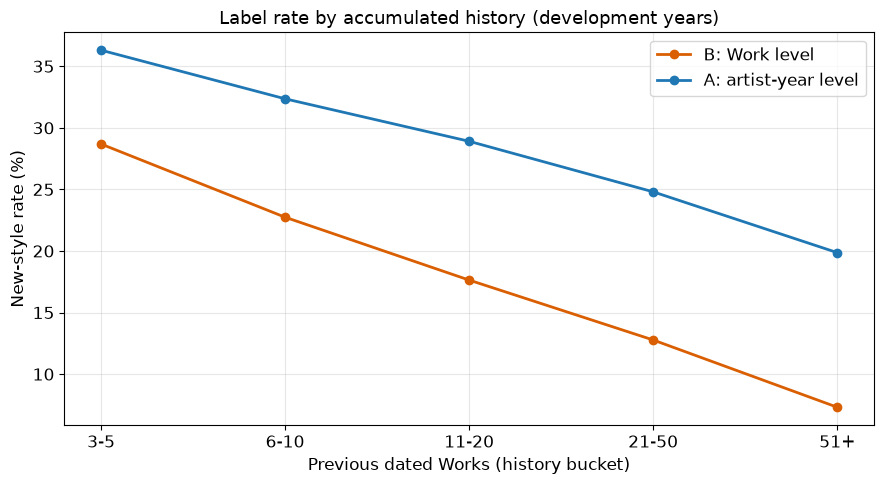

In [16]:
buckets = by_bucket.index.get_level_values('bucket').unique()  # history buckets in ascending order
fig, ax = plt.subplots(figsize=(9, 5))  # label rate by accumulated history, both levels
for level, color, label in [('work', COLOR_B, 'B: Work level'), ('artist_year', COLOR_A, 'A: artist-year level')]:  # same colours as the other charts
    series = by_bucket.xs(level, level='level')['prevalence'] * 100  # rate in %
    ax.plot(buckets, series.loc[buckets].values, marker='o', linewidth=2, color=color, label=label)  # one line per level
ax.set_xlabel('Previous dated Works (history bucket)')  # axis label
ax.set_ylabel('New-style rate (%)')  # axis label with unit
ax.set_title('Label rate by accumulated history (development years)')  # chart title
ax.legend()  # level names
ax.grid(alpha=0.3)  # light guide lines
plt.tight_layout()  # avoid clipped labels
plt.show()  # draw the chart

In [17]:
from what_target import prevalence_by_next_year_volume  # label rate by next-year volume, lives in src/what_target.py

volume = prevalence_by_next_year_volume(artist_years)  # dict: by_volume, cross, volume_predictability
display(volume['by_volume'].round(4))  # rate and share of rows by next-year volume
display(volume['cross']['labelled_rows'])  # labelled rows per history bucket and volume bucket
display(volume['cross']['prevalence'].round(4))  # rate per history bucket and volume bucket
volume['volume_predictability'].round(4)  # how well this year's Work count predicts a single-Work next year

,labelled_rows,row_share,prevalence
volume_bucket,,,
1,434567,0.5693,0.2541
2,153084,0.2005,0.3348
3-4,113464,0.1486,0.3968
5+,62256,0.0816,0.4719


volume_bucket,1,2,3-4,5+
prior_work_bucket,,,,
3-5,174575,46982,26862,9468
6-10,111705,37760,25846,10563
11-20,75626,31250,25187,12959
21-50,51288,25220,23320,15760
51+,21373,11872,12249,13506


volume_bucket,1,2,3-4,5+
prior_work_bucket,,,,
3-5,0.3103,0.4282,0.5128,0.5889
6-10,0.2590,0.3649,0.4496,0.5499
11-20,0.2135,0.3041,0.3879,0.5017
21-50,0.1695,0.2349,0.3088,0.4348
51+,0.1169,0.1626,0.2166,0.3437


,rows,share_next_year_single,spearman
volume_now_bucket,,,
1,417625.0,0.7150,NaN
2,157141.0,0.5272,NaN
3-4,120323.0,0.3552,NaN
5+,68282.0,0.1518,NaN
all,763371.0,0.5693,0.4281


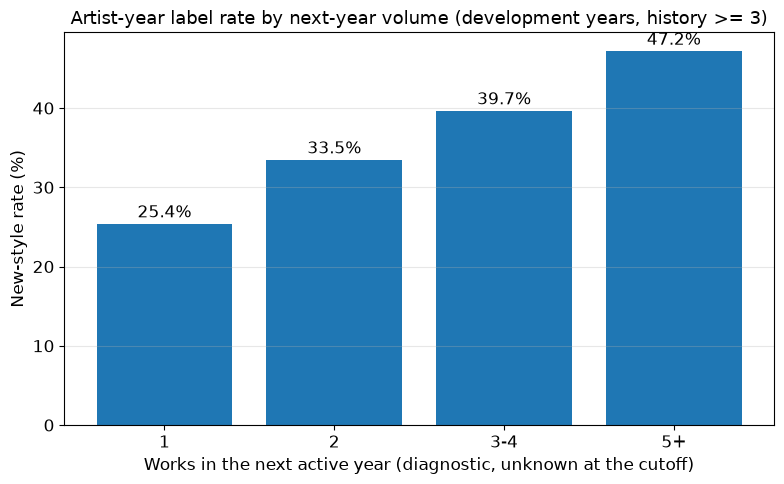

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))  # label rate by number of Works in the next active year
by_volume = volume['by_volume']  # four volume buckets
ax.bar(by_volume.index.astype(str), by_volume['prevalence'] * 100, color=COLOR_A)  # one bar per bucket
for position, value in enumerate(by_volume['prevalence'] * 100):  # rate written above each bar
    ax.text(position, value + 0.8, f"{value:.1f}%", ha='center')  # label with unit
ax.set_xlabel('Works in the next active year (diagnostic, unknown at the cutoff)')  # axis label
ax.set_ylabel('New-style rate (%)')  # axis label with unit
ax.set_title('Artist-year label rate by next-year volume (development years, history >= 3)')  # chart title
ax.grid(axis='y', alpha=0.3)  # light guide lines
plt.tight_layout()  # avoid clipped labels
plt.show()  # draw the chart

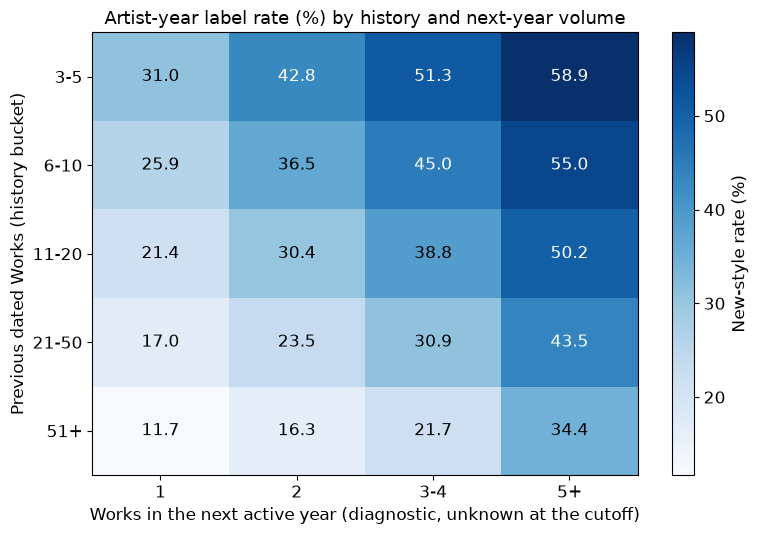

In [19]:
grid = volume['cross']['prevalence'] * 100  # rows: history bucket, columns: next-year volume bucket, in %
fig, ax = plt.subplots(figsize=(8, 5.5))  # heatmap of the cross table
image = ax.imshow(grid.values, cmap='Blues', aspect='auto')  # darker means a higher rate
for i in range(grid.shape[0]):  # one annotation per cell
    for j in range(grid.shape[1]):  # rate written in the cell
        ax.text(j, i, f"{grid.values[i, j]:.1f}", ha='center', va='center', color='white' if grid.values[i, j] > 40 else 'black')  # white text on dark cells
ax.set_xticks(range(grid.shape[1]), labels=grid.columns)  # volume buckets
ax.set_yticks(range(grid.shape[0]), labels=grid.index)  # history buckets
ax.set_xlabel('Works in the next active year (diagnostic, unknown at the cutoff)')  # axis label
ax.set_ylabel('Previous dated Works (history bucket)')  # axis label
ax.set_title('Artist-year label rate (%) by history and next-year volume')  # chart title
fig.colorbar(image, ax=ax, label='New-style rate (%)')  # colour scale with unit
plt.tight_layout()  # avoid clipped labels
plt.show()  # draw the chart

### Interpretation

**History.** Both labels fall with every step of accumulated history. At artist-year level (A) the rate falls from 36.3% (3-5 previous Works) to 19.9% (51+); at Work level (B) from 28.7% to 7.3%. The artist-year slope is much flatter: the last bucket keeps over half of the first bucket's rate at A, about a quarter at B. The artist-year table also has far fewer rows in the heavy buckets (51+ is 6.5% of artist-year rows against 11.8% of Work rows), because prolific artists collapse into one row per year.

**Volume.** The artist-year label depends strongly on how many Works the artist releases in the next active year: 25.4% with one Work, 33.5% with two, 39.7% with three or four and 47.2% with five or more. More Works give more chances to contain a new style, so part of the label is mechanical. This volume is not known at the cutoff and is used here only as a diagnostic.

**History with volume held fixed.** The history gradient survives inside every volume column: from 31.0% to 11.7% across history buckets when the next year has one Work, and from 58.9% to 34.4% when it has five or more. The gradient is therefore not only an effect of prolific artists releasing more Works. Volume is also partly predictable from the current year: the Spearman correlation between this year's and next year's Work count is 0.43, and 71.5% of artist-years with one Work are followed by a single-Work year, against 15.2% for artist-years with five or more. A model that sees the current Work count therefore picks up part of the volume effect indirectly.

### Decision

Next-year volume is a diagnostic only and never a model input. WHAT measures a volume-dependent event, and the documentation and the demo must say so. The flatter artist-year history gradient is consistent with this volume effect. Logged in `docs/decisions.md`.


## 6. Folds and the Exact Resolution Rule

### Question: which train rows are safe for each test tranche, when the label of an artist-year resolves only at its next active year, which can be many years away?

For WHEN, a fixed 2-year gap before each tranche is enough, because the label looks 1 to 2 years ahead. For WHAT the label is the next active year, so a train row from long before the test can still have a label that resolves inside the test tranche. The folds use the same five tranches as WHEN (1993-1997 to 2013-2017) with an exact rule on the train side: keep a train row only if its next active year is earlier than the test start.

In [20]:
from backtesting import fold_summary, make_what_folds  # fold builder with the resolution rule and the shared summary, live in src/backtesting.py

folds = make_what_folds(what_table)  # five walk-forward folds, development years only
fold_summary(folds).drop(columns=['gap_rows', 'test_rows_raw', 'censored_rows'])  # sizes per fold; the dropped columns repeat other columns for WHAT

,train_years,gap_years,test_years,train_rows,test_rows,test_artists,test_rows_with_train_artist,history_median,dropped_by_resolution_rule,test_rows_label_beyond_tranche,share_with_train_artist
fold,,,,,,,,,,,
1,1897-1991,resolution rule,1993-1997,232404,58141,30253,26801,8.0,26946,25482,0.460966
2,1897-1996,resolution rule,1998-2002,282606,74558,38845,33512,7.0,34885,32826,0.449476
3,1897-2001,resolution rule,2003-2007,347763,93072,48911,43570,7.0,44286,40895,0.468132
4,1897-2006,resolution rule,2008-2012,430809,121659,64168,52568,7.0,54312,52741,0.432093
5,1897-2011,resolution rule,2013-2017,539157,156591,79182,70227,8.0,67623,61659,0.448474


In [21]:
from what_target import fixed_gap_comparison  # exact rule against the fixed gap, lives in src/what_target.py

gap_table = fixed_gap_comparison(what_table)  # one row per fold, no label column is read
gap_table.round(4).T  # folds as columns, so the long names stay readable

fold,1,2,3,4,5
test_years,1993-1997,1998-2002,2003-2007,2008-2012,2013-2017
train_rows_exact,232404,282606,347763,430809,539157
train_rows_fixed_gap,240432,292085,360201,445369,553049
dropped_by_exact_rule,26946,34885,44286,54312,67623
dropped_by_fixed_gap,18918,25406,31848,39752,53731
fixed_gap_rows_resolving_at_or_after_start,13202,16096,20603,24696,28508
fixed_gap_resolving_share,0.0549,0.0551,0.0572,0.0555,0.0515
rows_kept_by_exact_rule_but_dropped_by_gap,5174,6617,8165,10136,14616
net_train_difference,-8028,-9479,-12438,-14560,-13892
net_train_difference_share,-0.0334,-0.0325,-0.0345,-0.0327,-0.0251


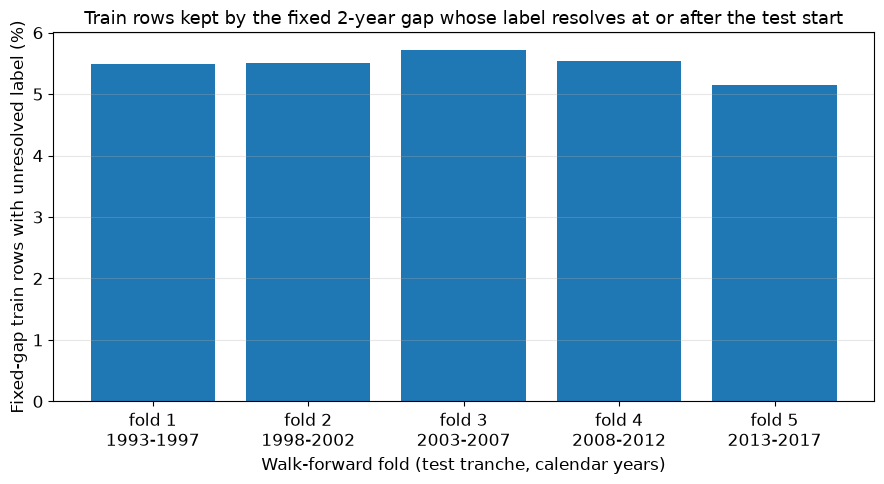

In [22]:
fig, ax = plt.subplots(figsize=(9, 5))  # share of fixed-gap train rows whose label is not resolved at the test start
ax.bar(gap_table.index, gap_table['fixed_gap_resolving_share'] * 100, color=COLOR_A)  # one bar per fold
ax.set_xticks(gap_table.index, labels=[f"fold {k}\n{years}" for k, years in gap_table['test_years'].items()])  # fold number and test tranche
ax.set_xlabel('Walk-forward fold (test tranche, calendar years)')  # axis label
ax.set_ylabel('Fixed-gap train rows with unresolved label (%)')  # axis label with unit
ax.set_title('Train rows kept by the fixed 2-year gap whose label resolves at or after the test start')  # chart title
ax.grid(axis='y', alpha=0.3)  # light guide lines
plt.tight_layout()  # avoid clipped labels
plt.show()  # draw the chart

### Interpretation

The five test tranches are the same as in WHEN. Train sets grow from 232,404 to 539,157 rows, test sets from 58,141 to 156,591 rows, and the exact rule drops 26,946 to 67,623 earlier rows per fold because their label resolves at or after the test start. The history median of the test rows is 7 to 8 previous Works, and 43.2% to 46.8% of test rows belong to artists that also have train rows, which is not leakage because the features are point-in-time safe and the train labels are resolved before the test starts. Between 39.4% and 44.0% of test rows have a label that looks beyond the end of their tranche (25,482 of 58,141 in fold 1 and 61,659 of 156,591 in fold 5), the same situation as the WHEN test labels.

Against the fixed 2-year gap of WHEN, 5.2% to 5.7% of the fixed-gap train rows (13,202 to 28,508 rows) have a label that is not yet resolved at the test start, because the next active year can be much more than 2 years away. The fixed gap would let all of them into training. The exact rule removes them and also keeps 5,174 to 14,616 recent rows per fold that the fixed gap would discard but whose label resolved in time. The net effect is a smaller train set: 8,028 to 14,560 fewer rows per fold, 2.5% to 3.5% of the fixed-gap train rows.

### Decision

The exact label-resolution rule replaces the fixed gap for WHAT: a train row is kept only if its `next_active_year` is earlier than the test start. The cost is a net loss of 2.5% to 3.5% of train rows. Logged in `docs/decisions.md`.


## 7. Baselines

### Question: what do simple rules that use only information known at the cutoff achieve on the five folds, and which one is the reference a model has to beat?

Three baselines, all fitted on the train rows of each fold only. (a) The constant train rate. (b) The train rate of the row's history bucket (previous dated Works: 3-5, 6-10, 11-20, 21-50, 51+). (c) The train rate of the row's history bucket and current-year volume bucket (Works in the current year: 1, 2, 3-4, 5+). A cell with fewer than 30 train rows, or one never seen in train, falls back to the global train rate. Next-year volume is never used.

In [23]:
from what_target import run_what_baselines  # three-baseline ladder on the WHAT folds, lives in src/what_target.py

baselines = run_what_baselines(what_table)  # constant, history lookup, history and volume lookup, scored with the artist-clustered bootstrap
ladder = baselines['ladder']  # one row per baseline and fold
ladder.round(4)  # PR-AUC, 95% interval, half-width in points, positive rate, ROC-AUC, train and test rows

test_years  pr_auc  pr_auc_lo  pr_auc_hi  \
baseline         fold                                            
a_constant       1     1993-1997  0.3064     0.3020     0.3104   
                 2     1998-2002  0.3018     0.2982     0.3054   
                 3     2003-2007  0.3161     0.3128     0.3191   
                 4     2008-2012  0.3266     0.3239     0.3294   
                 5     2013-2017  0.3228     0.3202     0.3253   
b_history        1     1993-1997  0.3381     0.3330     0.3433   
                 2     1998-2002  0.3356     0.3310     0.3404   
                 3     2003-2007  0.3533     0.3491     0.3573   
                 4     2008-2012  0.3615     0.3581     0.3651   
                 5     2013-2017  0.3581     0.3551     0.3614   
c_history_volume 1     1993-1997  0.3474     0.3418     0.3531   
                 2     1998-2002  0.3479     0.3428     0.3534   
                 3     2003-2007  0.3625     0.3582     0.3670   
                 4     2008-2012  0.3698     0.3660     0.3737   
                 5     2013-2017  0.3597     0.3564     0.3634   

                       ci_half_width_points  positive_rate  roc_auc  \
baseline         fold                                                 
a_constant       1                   0.4197         0.3064   0.5000   
                 2                   0.3612         0.3018   0.5000   
                 3                   0.3144         0.3161   0.5000   
                 4                   0.2732         0.3266   0.5000   
                 5                   0.2572         0.3228   0.5000   
b_history        1                   0.5172         0.3064   0.5590   
                 2                   0.4670         0.3018   0.5639   
                 3                   0.4077         0.3161   0.5680   
                 4                   0.3508         0.3266   0.5636   
                 5                   0.3144         0.3228   0.5636   
c_history_volume 1                   0.5650         0.3064   0.5672   
                 2                   0.5332         0.3018   0.5744   
                 3                   0.4428         0.3161   0.5752   
                 4                   0.3850         0.3266   0.5708   
                 5                   0.3529         0.3228   0.5633   

                       train_rows  test_rows  
baseline         fold                         
a_constant       1         232404      58141  
                 2         282606      74558  
                 3         347763      93072  
                 4         430809     121659  
                 5         539157     156591  
b_history        1         232404      58141  
                 2         282606      74558  
                 3         347763      93072  
                 4         430809     121659  
                 5         539157     156591  
c_history_volume 1         232404      58141  
                 2         282606      74558  
                 3         347763      93072  
                 4         430809     121659  
                 5         539157     156591

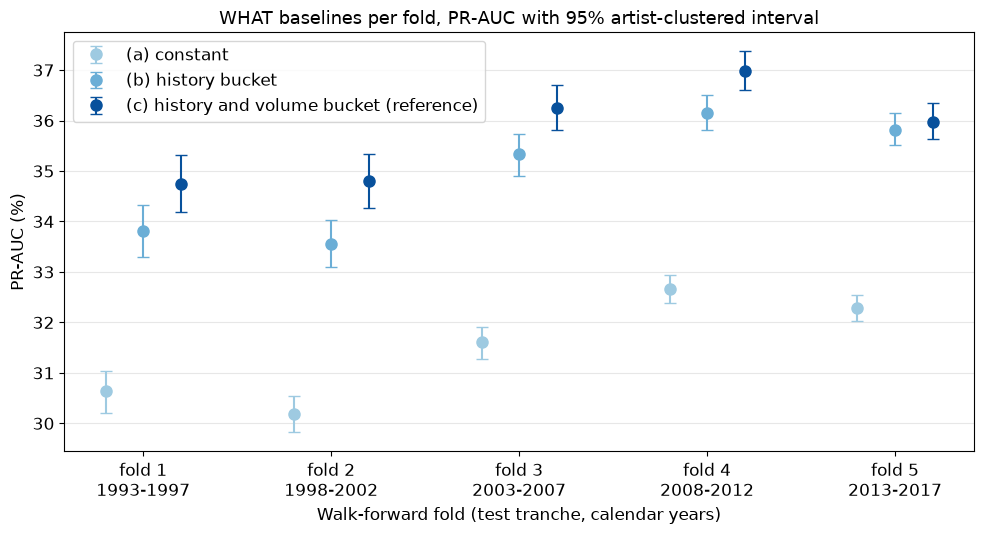

In [24]:
fig, ax = plt.subplots(figsize=(10, 5.5))  # PR-AUC per fold, one marker with its 95% interval per baseline
styles = {'a_constant': ('(a) constant', '#9ecae1', -0.2), 'b_history': ('(b) history bucket', '#6baed6', 0.0), 'c_history_volume': ('(c) history and volume bucket (reference)', '#08519c', 0.2)}  # label, colour (shades of the artist-year colour), horizontal offset
for name, (label, color, offset) in styles.items():  # one series per baseline
    rows = ladder.loc[name]  # five folds of this baseline
    yerr = [(rows['pr_auc'] - rows['pr_auc_lo']) * 100, (rows['pr_auc_hi'] - rows['pr_auc']) * 100]  # distance to the interval bounds, in points
    ax.errorbar(rows.index + offset, rows['pr_auc'] * 100, yerr=yerr, fmt='o', color=color, capsize=4, markersize=8, label=label)  # marker with error bars
ax.set_xticks(range(1, 6), labels=[f"fold {k}\n{years}" for k, years in ladder.loc['c_history_volume', 'test_years'].items()])  # fold number and test tranche
ax.set_xlabel('Walk-forward fold (test tranche, calendar years)')  # axis label
ax.set_ylabel('PR-AUC (%)')  # axis label with unit
ax.set_title('WHAT baselines per fold, PR-AUC with 95% artist-clustered interval')  # chart title
ax.legend(loc='upper left')  # baseline names
ax.grid(axis='y', alpha=0.3)  # light guide lines
plt.tight_layout()  # avoid clipped labels
plt.show()  # draw the chart

In [25]:
lifts = baselines['lifts']  # one row per fold, lifts between the three baselines in PR-AUC points
lifts[['test_years', 'lift_c_over_a', 'lift_c_over_b', 'lift_b_over_a']].round(3)  # (c) history and volume, (b) history, (a) constant

,test_years,lift_c_over_a,lift_c_over_b,lift_b_over_a
fold,,,,
1,1993-1997,4.107,0.932,3.175
2,1998-2002,4.612,1.231,3.380
3,2003-2007,4.643,0.917,3.726
4,2008-2012,4.316,0.826,3.490
5,2013-2017,3.688,0.154,3.535


In [26]:
lifts[['test_years', 'lift_c_over_b', 'reference_ci_half_width_points', 'two_half_widths_points', 'flag_ci_overlap_c_vs_b']].round(3)  # difference needed for two CIs of the width of (c) to separate, against the actual lift of (c) over (b)

,test_years,lift_c_over_b,reference_ci_half_width_points,two_half_widths_points,flag_ci_overlap_c_vs_b
fold,,,,,
1,1993-1997,0.932,0.565,1.130,True
2,1998-2002,1.231,0.533,1.066,False
3,2003-2007,0.917,0.443,0.886,False
4,2008-2012,0.826,0.385,0.770,False
5,2013-2017,0.154,0.353,0.706,True


### Interpretation

The constant baseline (a) has a PR-AUC equal to the test positive rate and a ROC-AUC of 0.500 in every fold, as designed: it cannot rank rows. Adding history (b) lifts PR-AUC by 3.2 to 3.7 points over (a) in every fold, with clearly separated intervals. Adding the current-year Work count on top of history (c) adds a further 0.15 to 1.2 points over (b): +0.93, +1.23, +0.92, +0.83 and +0.15 in folds 1 to 5. ROC-AUC stays low for both (0.559 to 0.568 for (b), 0.563 to 0.575 for (c)), so the information available through these buckets is weak.

The interval half-width of (c) falls from 0.57 points in fold 1 to 0.35 in fold 5. Two intervals of that width separate only if the difference exceeds twice the half-width: 1.13, 1.07, 0.89, 0.77 and 0.71 points in folds 1 to 5. The flag computed from the actual intervals of (c) and (b) is False in folds 2 to 4 and True in folds 1 and 5. In fold 1 the lift (0.93) is below twice the half-width of (c) (1.13) and the intervals overlap. In folds 2 to 4 the lifts (1.23, 0.92 and 0.83) exceed twice the half-width of (c) (1.07, 0.89 and 0.77) and the actual intervals are separate, but by thin margins (+0.24, +0.09 and +0.09 points); the table gives the order of magnitude, the flag gives the exact answer.

**Fold 5 observation.** In fold 5, the most recent tranche, the current-year Work count adds only 0.15 points to history and the intervals of (c) and (b) overlap. In that tranche the volume bucket carries almost no information beyond history. The reason was not investigated here.

### Decision

The reference for the kill gate is baseline (c), history bucket and current-year volume bucket, the strongest information available at the cutoff. A model has to beat (c), not the constant. Logged in `docs/decisions.md`.


## 8. Kill Gate Pass Rule

### Question: what must a WHAT model show to pass, fixed before any model result exists so that the verdict cannot be shaped by the result?

This section is markdown only. The rule below is fixed before any WHAT model result exists.

### The rule

A WHAT model passes only if both parts hold:

- **(a) Consistent and large enough improvement.** In at least 4 of the 5 development folds, the lower bound of the model's 95% artist-clustered bootstrap interval for PR-AUC is above the upper bound of the interval of baseline (c), and the PR-AUC improvement over baseline (c) in those folds is at least 1.0 point (absolute PR-AUC).
- **(b) No clear regression.** In no fold does the model's interval lie entirely below the interval of baseline (c).

### Why this shape

- **Four of five folds.** The folds are expanding-window tranches that share artists, so they are not independent. The rule is a consistency criterion, not a probability statement. Requiring all five folds would let one atypical tranche decide (fold 1 trains on the least and oldest data, and fold 5 already shows an anomaly where volume adds almost nothing). Requiring only the latest tranche would ignore stability over time. Clause (b) makes sure the one tolerated failure cannot be a clear regression. The value 4 is a convention fixed in advance.
- **A margin of 1.0 point.** With 58,141 to 156,591 test rows per fold the interval half-width of the baselines is below 0.6 points (0.35 to 0.57 for baseline (c) in section 7), so a rule based only on separated intervals could be passed by differences too small to matter. The margin separates what is statistically distinguishable from what is practically relevant. It is anchored on the data: adding the current-year Work count to history improved PR-AUC by 0.15 to 1.2 points, so style features are required to add at least as much as a simple Work count. It is also above the separation threshold of the CI table in section 7 in folds 3 to 5 (0.89, 0.77 and 0.71 points) and below it in folds 1 and 2 (1.13 and 1.07). The rule was fixed at 90% before any WHAT model result existed; its confidence level, half-widths and margin rationale are restated at 95% afterwards (see `docs/decisions.md`, "Confidence level moved from 90% to 95%"). It remains a judgment value, not a derived one.
- **Reporting.** Results are shown fold by fold with the margin in each fold, overall and by primary genre, because the labelled population over-represents genres whose Works carry style tags (section 4). Passing the gate only authorizes further work on WHAT. The sealed holdout is evaluated once at the end, as for WHEN.


## 9. Open Items

### Status and next steps

- **Done: style features.** The 23 style feature columns are built at the end of each artist-year and passed a point-in-time audit (section 10). `n_works_next_year` and any quantity derived from the label stay diagnostics and never become features.
- **Done: gate run.** The model was trained on the folds of section 6, scored fold by fold against baseline (c) and judged with the pass rule of section 8. The verdict is PASS (section 11), and the diagnostics of section 12 led to no feature change.
- **Done: 5-model comparison and staged XGBoost tuning,** on the same folds and the same 25 inputs (`05_what_models.ipynb`). Stage 0 was kept after the tuning (`docs/decisions.md`, "WHAT XGBoost adoption evaluation: stage 0 kept").
- **Done: sealed holdout.** The holdout (labelled test rows of 2018 to 2022) was evaluated once, at the end, after the gate passed. The training set for that evaluation keeps a development row only if its `next_active_year` is earlier than 2018. The test rows are the labelled rows whose `next_active_year` is 2023 or earlier, so 2023 has no labelled rows and the effective labelled test window is 2018 to 2022. Both rules are logged in `docs/decisions.md` ("WHAT holdout label rule"). The result is in `05_what_models.ipynb`.
- **Optional: sensitivity analysis.** The tolerant target (next active year that has style tags) is run only after the gate verdict and only if time allows, as a robustness check, never mixed into the main training set.


## 10. Feature Audit

### Question: does any WHAT feature use Works dated after its own year, or Works with no date?

The 23 feature columns of `build_what_features` are defined at the end of each artist-year from dated Works up to that year. Two checks test this on a seeded sample of 30,000 artists. (1) For the cutoffs 1990, 2000 and 2010, every dated Work after the cutoff is removed (undated Works are kept), the features are rebuilt, and each column is compared with the full build on the rows up to the cutoff. A point-in-time safe feature must show 0 differing rows. `new_style_year` and `n_works_next_year` look forward by design, so they must differ: they are positive controls that show the test can detect a leak. (2) The features are rebuilt without any undated Work and compared on every row; all differences must be 0.

The 23 columns fall in four families: vocabulary size (`n_styles_seen`, `n_styles_year`, `styles_per_work`, `top_style_share`, `n_genres_seen`), novelty (`n_new_styles_year`, `new_style_rate_so_far`, `years_since_new_style`), timing and format (`years_since_prev_active_year`, `years_active_so_far`, `albums_share_year`, `singles_share_year`) and one True / False flag per genre of the year's Works (11 columns). A year counts for novelty only if it has style tags and the artist already has a dated style vocabulary, so the first active year and the first year with tags are not novelty.

Only differences between two builds are counted. No label rate is computed, and no year from 2018 on is used.

In [27]:
from what_target import what_point_in_time_check, what_undated_check  # feature audit functions, live in src/what_target.py

audit = {cutoff: what_point_in_time_check(works_df, cutoff) for cutoff in (1990, 2000, 2010)}  # one table per cutoff, features and the two positive controls
print('rows compared per cutoff:', {cutoff: int(table['rows_compared'].iloc[0]) for cutoff, table in audit.items()})  # sample size of each comparison
display(pd.DataFrame({cutoff: table['rows_differ'] for cutoff, table in audit.items()}).rename_axis('rows that differ'))  # 0 for every feature, above 0 for the two controls
undated = what_undated_check(works_df)  # same sample, features with and without all undated Works
print('undated check, rows compared:', int(undated['rows_compared'].iloc[0]))  # one row per artist-year of the sample
undated[['rows_differ', 'differ_nan_vs_value']]  # must be 0 in every column

rows compared per cutoff: {1990: 21825, 2000: 34781, 2010: 54068}


,1990,2000,2010
rows that differ,,,
n_styles_seen,0,0,0
n_styles_year,0,0,0
n_new_styles_year,0,0,0
styles_per_work,0,0,0
new_style_rate_so_far,0,0,0
years_since_new_style,0,0,0
years_since_prev_active_year,0,0,0
years_active_so_far,0,0,0
top_style_share,0,0,0


undated check, rows compared: 95346


,rows_differ,differ_nan_vs_value
column,,
n_styles_seen,0,0
n_styles_year,0,0
n_new_styles_year,0,0
styles_per_work,0,0
new_style_rate_so_far,0,0
years_since_new_style,0,0
years_since_prev_active_year,0,0
years_active_so_far,0,0
top_style_share,0,0


### Interpretation

All 23 feature columns show 0 differing rows at the three cutoffs (21,825, 34,781 and 54,068 rows compared), so no feature uses a Work dated after its own year. The two positive controls do differ (`new_style_year` in 1,671, 2,830 and 4,228 rows, `n_works_next_year` in 2,096, 3,487 and 5,069), which shows the test can detect a leak. The undated check compares 95,346 rows and finds 0 differences, so undated Works enter no feature. Limits: the cut is at year level (not a blind spot here, because every feature is defined at the end of its year), the sample is 30,000 random artists, and `new_style_rate_so_far` passes by construction.

### Decision

The 23 features are point-in-time safe and are used as they are. Logged in `docs/decisions.md`.

## 11. Kill Gate

### Question: does the WHAT model, trained with the style features, beat baseline (c) on the five development folds under the rule fixed in section 8, so that WHAT earns a place in the project?

The model is XGBoost with the settings of the WHEN stage 0 (300 rounds, depth 6, minimum child weight 50, seed 1, no imputation, NaN handled natively, no class weights), one configuration and no tuning. Its 25 inputs are `history_count`, `n_works_year` and the 23 style columns of section 10 (vocabulary, novelty, timing and format, genre flags); next-year quantities are never inputs. It is fitted on each fold's train rows (those whose label resolved before the test starts) and scored on the fold's test tranche, against baseline (c), with the same folds, bootstrap size, confidence and seed as the baselines of section 7. Baseline (c) must reproduce the values of section 7, and the model must not give constant scores; both are asserted. Only development years are used, and the sealed holdout is untouched.

In [28]:
from what_target import build_what_features, run_what_gate  # style features and the kill gate run, live in src/what_target.py

features = build_what_features(works_df)  # 23 style feature columns per artist-year, from dated Works up to each year only (audited in section 10)
gate = run_what_gate(works_df, what_table, features=features)  # XGBoost stage 0 on 25 inputs against baseline (c), five development folds, pass rule of section 8
gate['folds'][['test_years', 'train_rows', 'test_rows', 'test_artists', 'distinct_model_scores', 'positive_rate', 'model_pr_auc', 'model_pr_auc_lo', 'model_pr_auc_hi', 'baseline_c_pr_auc', 'baseline_c_pr_auc_lo', 'baseline_c_pr_auc_hi']].round(4)  # one row per fold

,test_years,train_rows,test_rows,test_artists,distinct_model_scores,positive_rate,model_pr_auc,model_pr_auc_lo,model_pr_auc_hi,baseline_c_pr_auc,baseline_c_pr_auc_lo,baseline_c_pr_auc_hi
fold,,,,,,,,,,,,
1,1993-1997,232404,58141,30253,56289,0.3064,0.4607,0.4525,0.4681,0.3474,0.3418,0.3531
2,1998-2002,282606,74558,38845,71516,0.3018,0.4751,0.4680,0.4820,0.3479,0.3428,0.3534
3,2003-2007,347763,93072,48911,89305,0.3161,0.4946,0.4881,0.5006,0.3625,0.3582,0.3670
4,2008-2012,430809,121659,64168,116018,0.3266,0.4947,0.4898,0.4998,0.3698,0.3660,0.3737
5,2013-2017,539157,156591,79182,147792,0.3228,0.5002,0.4953,0.5053,0.3597,0.3564,0.3634


In [29]:
from sklearn.metrics import roc_auc_score  # ROC-AUC of the pooled test rows

display(gate['folds'][['improvement_points', 'ci_separated', 'rule_a_fold', 'rule_b_fold_fails']].round(4))  # improvement in points and the rule flags per fold
display(gate['verdict'].T)  # verdict, folds meeting rule (a), folds failing rule (b) and the improvement per fold
display(gate['by_genre'].round(4))  # descriptive view by primary genre, scores pooled over the five folds
scores = gate['scores']  # row-level scores of the pooled test rows
print('pooled ROC-AUC on', f"{len(scores):,}", 'test rows, model:', round(roc_auc_score(scores['label'], scores['model_score']), 4), '| baseline (c):', round(roc_auc_score(scores['label'], scores['c_score']), 4))  # ranking quality independent of the base rate

,improvement_points,ci_separated,rule_a_fold,rule_b_fold_fails
fold,,,,
1,11.3291,True,True,False
2,12.7195,True,True,False
3,13.2053,True,True,False
4,12.4971,True,True,False
5,14.0514,True,True,False


,verdict
result,PASS
folds_passing_a,5
min_folds_required,4
rule_a_met,True
folds_failing_b,0
rule_b_met,True
margin_points,1.0
improvement_points_fold_1,11.329138
improvement_points_fold_2,12.719453
improvement_points_fold_3,13.20534


,rows,positive_rate,model_pr_auc,baseline_c_pr_auc,difference_points
primary_genre,,,,,
all genres,504021,0.3175,0.4899,0.3628,12.7159
Electronic,195486,0.3737,0.4919,0.3977,9.4173
Rock,139203,0.2826,0.4284,0.3154,11.2967
Pop,50445,0.3056,0.5087,0.3759,13.2808
"Folk, World, & Country",38570,0.2117,0.4642,0.2652,19.8946
Jazz,20019,0.3118,0.5035,0.3814,12.2088
Hip Hop,19001,0.4038,0.6375,0.4316,20.5912
Reggae,11880,0.1935,0.3609,0.2642,9.6699
Latin,11619,0.2194,0.4176,0.2781,13.9499


pooled ROC-AUC on 504,021 test rows, model: 0.6732 | baseline (c): 0.5712


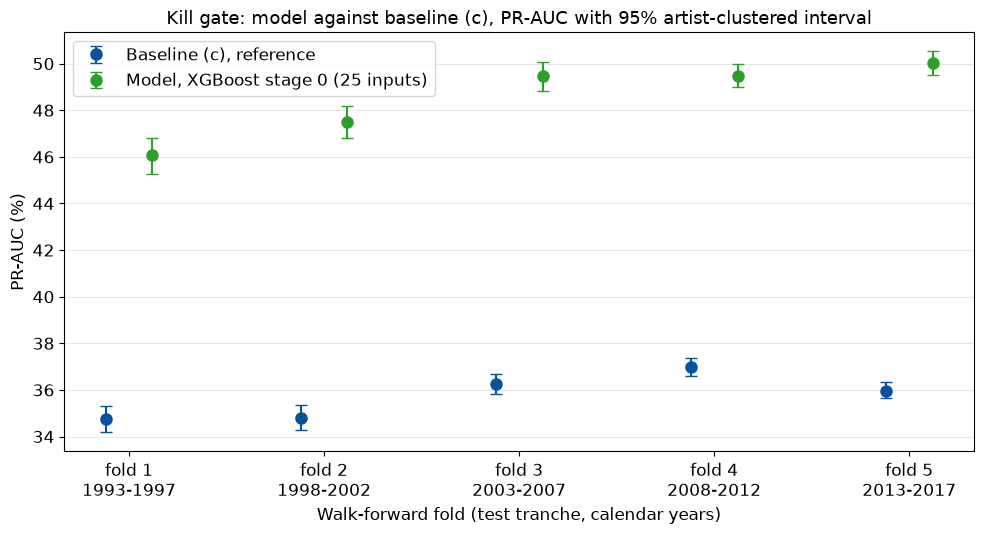

In [30]:
folds_gate = gate['folds']  # per-fold gate table
fig, ax = plt.subplots(figsize=(10, 5.5))  # PR-AUC per fold, model against baseline (c), with 95% intervals
for label, prefix, color, offset in [('Baseline (c), reference', 'baseline_c', '#08519c', -0.12), ('Model, XGBoost stage 0 (25 inputs)', 'model', '#2ca02c', 0.12)]:  # same blue as section 7 for (c)
    yerr = [(folds_gate[f'{prefix}_pr_auc'] - folds_gate[f'{prefix}_pr_auc_lo']) * 100, (folds_gate[f'{prefix}_pr_auc_hi'] - folds_gate[f'{prefix}_pr_auc']) * 100]  # distance to the interval bounds, in points
    ax.errorbar(folds_gate.index + offset, folds_gate[f'{prefix}_pr_auc'] * 100, yerr=yerr, fmt='o', color=color, capsize=4, markersize=8, label=label)  # marker with error bars
ax.set_xticks(range(1, 6), labels=[f"fold {k}\n{years}" for k, years in folds_gate['test_years'].items()])  # fold number and test tranche
ax.set_xlabel('Walk-forward fold (test tranche, calendar years)')  # axis label
ax.set_ylabel('PR-AUC (%)')  # axis label with unit
ax.set_title('Kill gate: model against baseline (c), PR-AUC with 95% artist-clustered interval')  # chart title
ax.legend(loc='upper left')  # run names
ax.grid(axis='y', alpha=0.3)  # light guide lines
plt.tight_layout()  # avoid clipped labels
plt.show()  # draw the chart

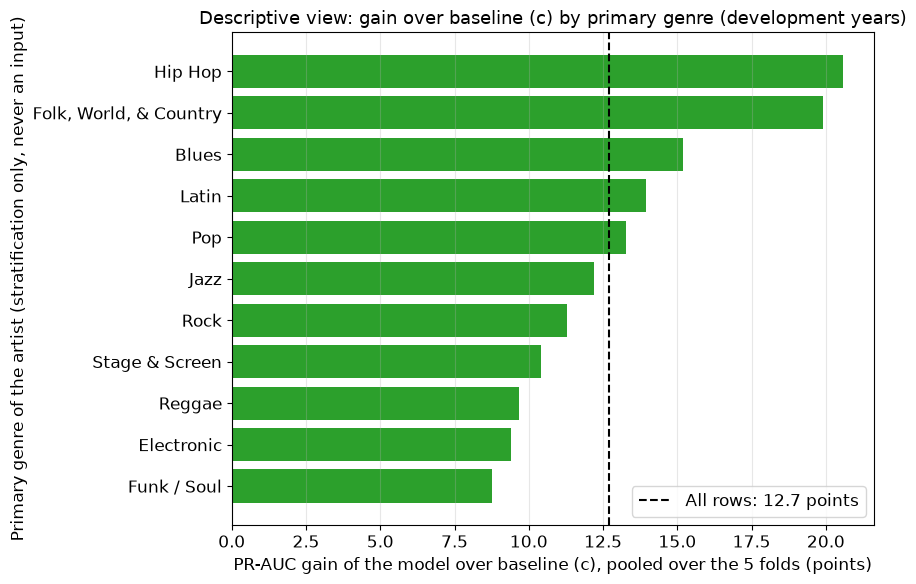

In [31]:
genre_gain = gate['by_genre'].drop(index='all genres').sort_values('difference_points')  # primary genres, smallest gain first
overall_gain = gate['by_genre'].loc['all genres', 'difference_points']  # gain over all rows, the reference line
fig, ax = plt.subplots(figsize=(9, 6))  # horizontal bars read best with long genre names
ax.barh(genre_gain.index, genre_gain['difference_points'], color='#2ca02c')  # one bar per primary genre
ax.axvline(overall_gain, color='black', linestyle='--', label=f"All rows: {overall_gain:.1f} points")  # overall reference
ax.set_xlabel('PR-AUC gain of the model over baseline (c), pooled over the 5 folds (points)')  # axis label with unit
ax.set_ylabel('Primary genre of the artist (stratification only, never an input)')  # axis label
ax.set_title('Descriptive view: gain over baseline (c) by primary genre (development years)')  # chart title
ax.legend(loc='lower right')  # reference line name
ax.grid(axis='x', alpha=0.3)  # light guide lines
plt.tight_layout()  # avoid clipped labels
plt.show()  # draw the chart

### Interpretation

The model is above baseline (c) in 5 of 5 folds, by +11.3 to +14.1 PR-AUC points with separated intervals, and rule (b) is broken in no fold, so the verdict is PASS as fixed in section 8. The pooled ROC-AUC is 0.6732 against 0.5712, and the model is above (c) in all 11 primary genres (+8.8 to +20.6 points, descriptive only, no decision on genres). The size of the gain, much larger than the contribution of history and volume, is examined in section 12.

### Decision

The verdict is PASS, as pre-registered. No rule, model setting or feature was changed after the result. WHAT continued to the 5-model comparison (done in `05_what_models.ipynb`), and the size of the gain is checked in section 12 without changing the verdict. Logged in `docs/decisions.md`.

## 12. Gate Diagnostics

### Question: the gain over baseline (c) (11.3 to 14.1 PR-AUC points) is large compared with history (3 to 4 points) and the current-year Work count (0.15 to 1.2 points); does it come from something other than a genuine signal in the style features?

Three doubts are checked. D1, artist memory: is the gain smaller for artists the model never saw in train? D2, volume effect: does the model only recognise artists who will release many Works next year? D4, feature source: which group of features carries the gain? D3 is not a separate test: it is the ROC-AUC check, reported next to PR-AUC inside D1 and D2, because PR-AUC depends on the base rate of each subset. All of them are post-hoc, use the development folds only, the same fold tables, bootstrap settings and seed as the gate, and one model configuration. They cannot rescue or overturn the verdict, which stands as pre-registered. D1 and D2 read the row-level scores of the gate without refitting; only D4 refits.

### D1: artist memory. Is the gain smaller for artists absent from the train table?

Each fold's test rows are split by whether the artist has any row in that fold's train table (returning) or not (new). If the gain came from memorising artists, it should be smaller for new artists. PR-AUC and ROC-AUC are shown together because PR-AUC depends on the base rate of each subset (D3, reported here and in D2).

In [32]:
from what_target import gate_diagnostic_returning_artists  # D1, new against returning artists, lives in src/what_target.py

d1 = gate_diagnostic_returning_artists(gate, what_table)  # D1 on the row-level scores of the gate, no refit
display(d1.loc['pooled'].round(4))  # pooled over the five folds: rows, share, positive rate, PR-AUC and ROC-AUC of the model and of (c)
d1['pr_difference_points'].unstack('subset')[['new', 'returning', 'all']].round(2)  # PR-AUC difference in points, per fold and pooled

,rows,share,positive_rate,model_pr_auc,model_roc_auc,c_pr_auc,c_roc_auc,pr_difference_points,roc_difference_points
subset,,,,,,,,,
new,277343.0,0.5503,0.3661,0.5323,0.6595,0.3788,0.5170,15.3413,14.2458
returning,226678.0,0.4497,0.2580,0.3950,0.6620,0.2904,0.5539,10.4567,10.8016
all,504021.0,1.0000,0.3175,0.4899,0.6732,0.3628,0.5712,12.7159,10.2014


subset,new,returning,all
scope,,,
fold 1,13.38,10.57,11.33
fold 2,15.10,11.03,12.72
fold 3,15.83,11.33,13.21
fold 4,15.06,9.96,12.50
fold 5,17.00,11.14,14.05
pooled,15.34,10.46,12.72


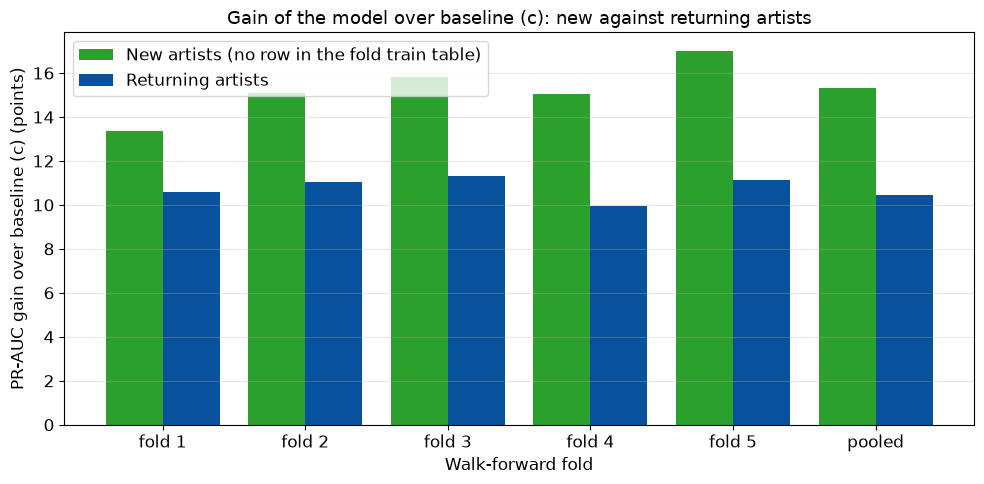

In [33]:
gain = d1['pr_difference_points'].unstack('subset')[['new', 'returning']]  # PR-AUC difference in points, per fold and pooled
fig, ax = plt.subplots(figsize=(10, 5))  # grouped bars, new against returning artists
positions = range(len(gain))  # one group per fold, then pooled
ax.bar([p - 0.2 for p in positions], gain['new'], width=0.4, color='#2ca02c', label='New artists (no row in the fold train table)')  # new artists
ax.bar([p + 0.2 for p in positions], gain['returning'], width=0.4, color='#08519c', label='Returning artists')  # returning artists
ax.set_xticks(list(positions), labels=gain.index)  # fold names and pooled
ax.set_xlabel('Walk-forward fold')  # axis label
ax.set_ylabel('PR-AUC gain over baseline (c) (points)')  # axis label with unit
ax.set_title('Gain of the model over baseline (c): new against returning artists')  # chart title
ax.legend()  # subset names
ax.grid(axis='y', alpha=0.3)  # light guide lines
plt.tight_layout()  # avoid clipped labels
plt.show()  # draw the chart

**Reading.** The gain is larger for artists with no row in the fold's train table: +15.3 PR-AUC points for new artists (55.0% of the test rows) against +10.5 for returning artists, and +14.2 against +10.8 points in ROC-AUC, with the new-artist gain larger in every fold. A per-artist memory explanation therefore cannot account for the gain for new artists; it does not exclude a contribution for returning artists. Logged in `docs/decisions.md`.

### D2: volume effect (with D3, the ROC-AUC check). Does the model only recognise artists who will release many Works next year?

The label is mechanically more frequent when the next year has more Works (section 5), so the model could be gaining only by recognising artists who will release many Works. The gate scores are stratified by the number of Works in the next active year (buckets 1, 2, 3-4, 5+). That count is joined only to stratify the scores, and it is never a model input. Pooled over folds and per fold, each bucket shows its share, positive rate and the PR-AUC and ROC-AUC of the model and of (c). A last table compares the ROC-AUC on all rows with the mean of the within-bucket values, to show how much of the ranking comes from separating buckets (volume) and how much from ranking inside a bucket.

In [34]:
from what_target import build_what_table, gate_diagnostic_next_year_volume  # table with the diagnostic column and D2, live in src/what_target.py

what_table_diag = build_what_table(artist_years, include_diagnostics=True)  # same rows plus n_works_next_year, used only to stratify the scores
d2 = gate_diagnostic_next_year_volume(gate, what_table_diag)  # D2 on the row-level scores of the gate, no refit
display(d2['by_bucket'].loc['pooled'].round(4))  # pooled over the five folds, per next-year volume bucket
display(d2['by_bucket']['pr_difference_points'].unstack('bucket').round(2))  # PR-AUC difference in points, per fold and bucket
d2['ranking'].round(4)  # ROC-AUC on all rows against the mean of the within-bucket values, model and baseline (c)

,rows,share,positive_rate,model_pr_auc,model_roc_auc,c_pr_auc,c_roc_auc,pr_difference_points,roc_difference_points
bucket,,,,,,,,,
1,308483.0,0.6120,0.2630,0.4334,0.6712,0.3004,0.5742,13.2978,9.7072
2,98331.0,0.1951,0.3584,0.5261,0.6668,0.4009,0.5788,12.5218,8.8004
3-4,66861.0,0.1327,0.4257,0.5873,0.6656,0.4666,0.5743,12.0727,9.1346
5+,30346.0,0.0602,0.4996,0.6565,0.6674,0.5317,0.5506,12.4779,11.6767
all,504021.0,1.0000,0.3175,0.4899,0.6732,0.3628,0.5712,12.7159,10.2014


bucket,1,2,3-4,5+,all
scope,,,,,
fold 1,11.60,9.84,9.17,12.19,11.33
fold 2,12.61,11.24,10.87,11.38,12.72
fold 3,14.30,11.16,10.43,10.44,13.21
fold 4,13.27,12.15,10.57,10.76,12.50
fold 5,13.97,14.04,14.53,14.64,14.05
pooled,13.30,12.52,12.07,12.48,12.72


,model_roc_all,model_roc_within_mean,model_roc_within_weighted,model_gap_points,c_roc_all,c_roc_within_mean,c_roc_within_weighted,c_gap_points
scope,,,,,,,,
fold 1,0.6690,0.6685,0.6664,0.2625,0.5672,0.5731,0.5730,-0.5844
fold 2,0.6781,0.6784,0.6731,0.5014,0.5744,0.5848,0.5792,-0.4796
fold 3,0.6825,0.6765,0.6783,0.4183,0.5752,0.5828,0.5787,-0.3432
fold 4,0.6677,0.6541,0.6619,0.5786,0.5708,0.5650,0.5709,-0.0031
fold 5,0.6708,0.6684,0.6687,0.2095,0.5633,0.5580,0.5662,-0.2902
pooled,0.6732,0.6678,0.6694,0.3789,0.5712,0.5695,0.5737,-0.2496


**Reading.** The model is above (c) in all four next-year volume buckets and in all five folds: PR-AUC +12.1 to +13.3 points pooled by bucket, and +9.2 to +14.6 points across fold and bucket. The pooled ROC-AUC on all rows is 0.6732 for the model against 0.6694 as the row-weighted mean of the within-bucket values (0.6678 unweighted), a gap of 0.4 points, so almost none of the ranking comes from separating the volume buckets (baseline (c): 0.5712 against 0.5737). D3 is covered by the ROC-AUC columns next to PR-AUC in D1 and D2. Logged in `docs/decisions.md`.

### D4: feature source. Which group of features carries the gain?

If one family of features carried the gain, it would show where it comes from and whether it can be trusted. The model is refitted five times with the same settings, folds, bootstrap and seed as the gate: on the two table inputs alone (`TABLE_INPUTS`, history and Work count), and on the full set minus each of `VOCABULARY` (5 inputs: `n_styles_seen`, `n_styles_year`, `styles_per_work`, `top_style_share`, `n_genres_seen`), `NOVELTY` (3: `n_new_styles_year`, `new_style_rate_so_far`, `years_since_new_style`), `TIMING_FORMAT` (4: `years_since_prev_active_year`, `years_active_so_far`, `albums_share_year`, `singles_share_year`) and `GENRE_FLAGS` (11, one per genre). The groups partition the 25 inputs exactly once. The full model and baseline (c) are reused from the gate.

In [35]:
from what_target import gate_diagnostic_feature_ablation  # D4, leave-one-group-out ablation with refits, lives in src/what_target.py

ablation = gate_diagnostic_feature_ablation(gate, what_table, features)  # groups TABLE_INPUTS, VOCABULARY, NOVELTY, TIMING_FORMAT, GENRE_FLAGS; same folds, bootstrap and seed as the gate
display(ablation['summary'].round(4))  # mean PR-AUC, differences in points and pooled ROC-AUC per run
display(ablation['folds']['pr_auc'].unstack('fold').round(4))  # PR-AUC per run and fold
ablation['folds']['diff_vs_c_points'].unstack('fold').round(2)  # difference against baseline (c) per run and fold, in points

,n_features,mean_pr_auc,mean_diff_vs_c_points,mean_diff_vs_full_points,pooled_roc_auc_all_rows,roc_diff_vs_full_points
run,,,,,,
full model (gate),25.0,0.4851,12.7605,0.0000,0.6732,0.0000
minus vocabulary,20.0,0.4695,11.2041,-1.5563,0.6604,-1.2766
minus novelty,22.0,0.4777,12.0282,-0.7323,0.6681,-0.5066
minus timing_format,21.0,0.4829,12.5490,-0.2115,0.6716,-0.1537
minus genre_flags,14.0,0.4769,11.9424,-0.8181,0.6649,-0.8281
table_inputs only,2.0,0.3630,0.5588,-12.2017,0.5739,-9.9249
baseline (c),NaN,0.3575,0.0000,-12.7605,0.5712,-10.2014


fold,1,2,3,4,5
run,,,,,
full model (gate),0.4607,0.4751,0.4946,0.4947,0.5002
minus vocabulary,0.4520,0.4588,0.4789,0.4773,0.4805
minus novelty,0.4553,0.4665,0.4866,0.4874,0.4929
minus timing_format,0.4562,0.4738,0.4923,0.4923,0.5002
minus genre_flags,0.4532,0.4669,0.4814,0.4867,0.4962
table_inputs only,0.3532,0.3524,0.3682,0.3763,0.3652
baseline (c),0.3474,0.3479,0.3625,0.3698,0.3597


fold,1,2,3,4,5
run,,,,,
full model (gate),11.33,12.72,13.21,12.50,14.05
minus vocabulary,10.45,11.09,11.64,10.75,12.08
minus novelty,10.79,11.86,12.40,11.76,13.32
minus timing_format,10.87,12.58,12.98,12.25,14.05
minus genre_flags,10.57,11.90,11.89,11.70,13.65
table_inputs only,0.58,0.44,0.57,0.65,0.55
baseline (c),0.00,0.00,0.00,0.00,0.00


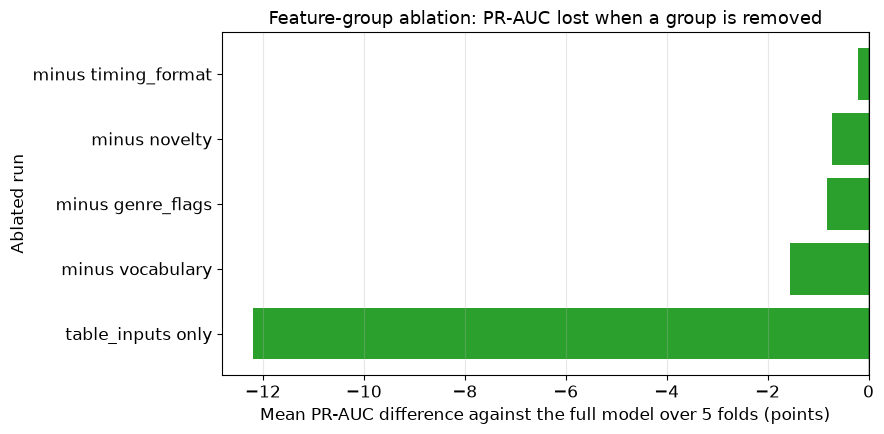

In [36]:
ablated = ablation['summary'].drop(index=['full model (gate)', 'baseline (c)']).sort_values('mean_diff_vs_full_points')  # the five ablated runs, largest loss first
fig, ax = plt.subplots(figsize=(9, 4.5))  # PR-AUC lost against the full model, in points
ax.barh(ablated.index, ablated['mean_diff_vs_full_points'], color='#2ca02c')  # one bar per ablated run
ax.axvline(0, color='black', linewidth=1)  # the full model
ax.set_xlabel('Mean PR-AUC difference against the full model over 5 folds (points)')  # axis label with unit
ax.set_ylabel('Ablated run')  # axis label
ax.set_title('Feature-group ablation: PR-AUC lost when a group is removed')  # chart title
ax.grid(axis='x', alpha=0.3)  # light guide lines
plt.tight_layout()  # avoid clipped labels
plt.show()  # draw the chart

**Reading.** Every ablated model stays above (c) in every fold, while the two table inputs alone are within +0.44 to +0.65 points of (c) (+0.56 on average): the gain needs the added columns, not history and the Work count. Removing VOCABULARY costs the most (-1.56 points of PR-AUC, pooled ROC-AUC 0.6604 against 0.6732), then GENRE_FLAGS (-0.82), NOVELTY (-0.73) and TIMING_FORMAT (-0.21), and any one removal leaves at least 11.2 of the 12.8 points over (c). These are hypotheses, not conclusions: no single group carries the gain, the groups overlap in what they tell the model, and novelty is not the main source. Leave-one-group-out understates each group under overlap and does not say which group would suffice alone.

**Decision.** No feature change follows, and the feature set stays at the 25 inputs. Logged in `docs/decisions.md`.

## Appendix A. Style versus Genre Change

### Question: how often does the next active year bring a new genre instead of a new style, and does a genre target carry anything the style target does not?

A new genre is defined like a new style, on the genre tags: the next active year brings a genre absent from every genre seen through the end of the current year (genres of undated Works count as seen, the stray tag "1" is excluded). This appendix is descriptive. It uses the same eligible rows as section 4 (development years, at least 3 previous Works) and does not feed the kill gate.

In [37]:
from what_target import build_artist_year_genres, genre_change_summary  # genre counterpart of the target and its summary, live in src/what_target.py

artist_year_genres = build_artist_year_genres(works_df)  # same rows as artist_years, genre label instead of style label
genre_summary = genre_change_summary(works_df, artist_years, artist_year_genres)  # dict of tables, development years and history >= 3 only
genre_summary['overall'].round(4)  # eligible rows, labelled rows and prevalence of each label

,eligible_rows,labelled_rows,unlabelled_rows,prevalence
new_style_year,1067817,763371,304446,0.3093
new_genre_year,1067817,888689,179128,0.0802


In [38]:
genre_summary['by_window'].round(4)  # both prevalences for the five WHEN test tranches

,eligible_rows,style_labelled_rows,style_prevalence,genre_labelled_rows,genre_prevalence
year,,,,,
1993-1997,80172,58141,0.3064,68348,0.0808
1998-2002,103420,74558,0.3018,87499,0.0752
2003-2007,131239,93072,0.3161,109154,0.0752
2008-2012,172976,121659,0.3266,140254,0.0708
2013-2017,228256,156591,0.3228,177763,0.0633


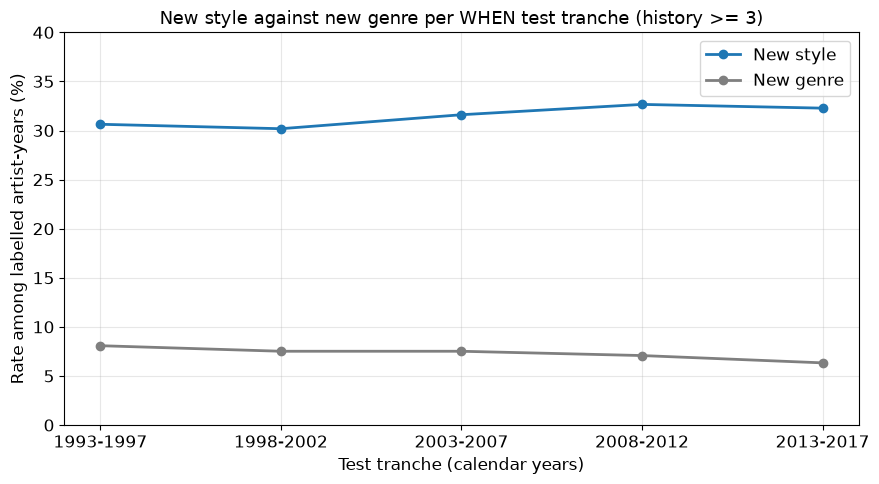

In [39]:
by_window_genre = genre_summary['by_window']  # one row per test tranche
fig, ax = plt.subplots(figsize=(9, 5))  # new style against new genre, per tranche
ax.plot(by_window_genre.index.astype(str), by_window_genre['style_prevalence'] * 100, marker='o', linewidth=2, color=COLOR_A, label='New style')  # style label
ax.plot(by_window_genre.index.astype(str), by_window_genre['genre_prevalence'] * 100, marker='o', linewidth=2, color='#7f7f7f', label='New genre')  # genre label, grey so it is not confused with levels A and B
ax.set_xlabel('Test tranche (calendar years)')  # axis label
ax.set_ylabel('Rate among labelled artist-years (%)')  # axis label with unit
ax.set_title('New style against new genre per WHEN test tranche (history >= 3)')  # chart title
ax.set_ylim(0, 40)  # common zero baseline so the gap is read at true size
ax.legend()  # label names
ax.grid(alpha=0.3)  # light guide lines
plt.tight_layout()  # avoid clipped labels
plt.show()  # draw the chart

In [40]:
display(genre_summary['crosstab'].round(4))  # 2x2 counts, conditional probabilities and the three-level split, on rows where both labels exist
display(genre_summary['style_missing_rows'].round(4))  # genre rate on the rows without style tags, next to the rows where both labels exist
genre_summary['by_history_bucket'].round(4)  # both prevalences by prior-work bucket

,rows,base,share
measure,,,
"style 0, genre 0",510744,763371,0.6691
"style 0, genre 1",16532,763371,0.0217
"style 1, genre 0",189413,763371,0.2481
"style 1, genre 1",46682,763371,0.0612
P(genre = 1 | style = 1),46682,236095,0.1977
P(style = 1 | genre = 1),46682,63214,0.7385
no new style and no new genre,510744,763371,0.6691
new style without new genre,189413,763371,0.2481
new genre (with or without new style),63214,763371,0.0828


,rows,genre_prevalence
genre label only (next year without style tags),125318,0.0646
both labels exist,763371,0.0828


,eligible_rows,style_labelled_rows,style_prevalence,genre_labelled_rows,genre_prevalence
prior_work_bucket,,,,,
3-5,406123,257887,0.3631,303164,0.0983
6-10,261646,185874,0.3236,217185,0.0843
11-20,188535,145022,0.2891,168176,0.0730
21-50,142289,115588,0.2480,133302,0.0607
51+,69224,59000,0.1987,66862,0.0422


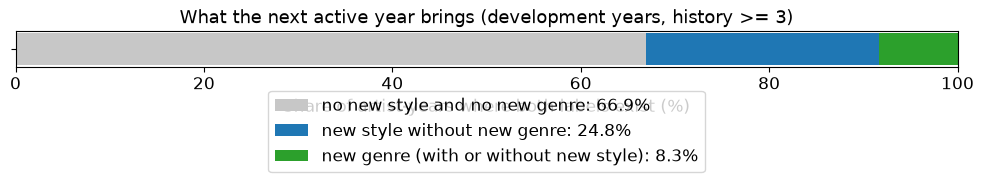

In [41]:
split = genre_summary['crosstab'].loc[['no new style and no new genre', 'new style without new genre', 'new genre (with or without new style)'], 'share'] * 100  # the three-level split, in %
fig, ax = plt.subplots(figsize=(10, 2.8))  # one horizontal stacked bar
left = 0  # start of the next segment
for (name, value), color in zip(split.items(), ['#c7c7c7', COLOR_A, '#2ca02c']):  # one segment per level
    ax.barh([''], [value], left=left, color=color, label=f"{name}: {value:.1f}%")  # segment with its share in the legend
    left += value  # next segment starts where this one ends
ax.set_xlim(0, 100)  # shares of the compared rows
ax.set_xlabel('Share of artist-years where both labels exist (%)')  # axis label with unit
ax.set_title('What the next active year brings (development years, history >= 3)')  # chart title
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.45), ncol=1)  # segment names below the axis
plt.tight_layout()  # avoid clipped labels
plt.show()  # draw the chart

### Interpretation

**Frequency.** A new genre is much rarer than a new style: 8.0% of 888,689 labelled artist-years against 30.9% of 763,371. The genre label also has more labelled rows, because every Work carries a valid genre: the 125,318 artist-years whose next year has no style tags are labelled for genre, and only the 179,128 without a next active year stay unlabelled.

**Over time and history.** The genre rate falls across the five tranches (8.1%, 7.5%, 7.5%, 7.1%, 6.3%), while the style rate stays between 30.2% and 32.7%. Both fall with accumulated history, genre from 9.8% in the 3-5 bucket to 4.2% in the 51+ bucket, style from 36.3% to 19.9%.

**Relation between the two.** On the 763,371 rows where both labels exist, 66.9% bring neither a new style nor a new genre, 24.8% a new style inside genres already seen, and 8.3% a new genre. A new genre without a new style is rare (2.2%). When a new genre appears, a new style appears too in 73.9% of cases; when a new style appears, a new genre appears in 19.8%. A genre change is therefore mostly implied by a style change, while most style changes stay inside known genres.

**Rows without style tags.** On the 125,318 rows whose next year has no style tags, the new genre rate is 6.5%, against 8.3% on the rows where both labels exist. The rows lost for the style target do not behave very differently on the genre label, but the two groups also differ in genre mix (section 4), so this is not a clean comparison.

### Decision

Styles stay the only primary target. A genre target would be rare, falling over time, limited to 11 possible values and mostly implied by a style change, so it adds little that the style target does not already measure. Genre is used to stratify the kill gate results, and the three-level split remains available for the demo narrative. Logged in `docs/decisions.md`.
